# Staphylococcus membrane diffusion maps
## 1. Problem
How can a fluorescence movie reveal molecular mobility in a bacterial membrane? We reconstruct **diffusion D, effective occupancy N and covariance offset c** in every fixed observed-cell aperture. This is a parameter-imaging inverse problem, not fluorescent-particle tracking or image enhancement.

The bound observation is a real Nile-red *S.aureus* movie at20°C, supplied with the2024Biophysical Journal study [Barbotin et al.](https://doi.org/10.1016/j.bpj.2024.06.012). We preserve the full native44161×12×80digital-count array. The paper's standard2×2spatial integration yields52fixed cell apertures on a6×40lattice; this coarse map is **not interpolated into apparent higher resolution**.

No independent molecular-diffusion truth exists for this movie. We distinguish the original code rerun on these exact observations, the fresh cleaned reconstruction below, and historical multi-acquisition paper findings. This one movie cannot establish population differences, biological replication or a temperature-response curve.

In [1]:
from pathlib import Path
import sys,time,json,warnings,importlib.util,os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm,LogNorm
from matplotlib.ticker import NullFormatter,NullLocator
from scipy.integrate import quad

TASK=Path.cwd()
if not (TASK/'data/raw_data.npz').is_file():
    TASK=TASK.parent if (TASK.parent/'data/raw_data.npz').is_file() else TASK.parent.parent
assert (TASK/'data/raw_data.npz').is_file()
sys.path.insert(0,str(TASK))
from src.preprocessing import prepare_stack,bin_labels
from src.solvers import reconstruct
from src.physics_model import correlation_model
from src.visualization import vector_metrics,normalized_residual,nonlinear_mse
spec=importlib.util.spec_from_file_location('review_judge',TASK/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
ARCHIVE=Path(os.environ['IMAGING101_REVIEW_ARCHIVE']) if os.environ.get('IMAGING101_REVIEW_ARCHIVE') else None
# Export is optional maintainer presentation only; reconstruction has no private dependency.
EXPORT=ARCHIVE/'figures' if ARCHIVE is not None and ARCHIVE.is_dir() else None
if EXPORT:EXPORT.mkdir(exist_ok=True)
figures=[];numeric={};experiment_records={}
def finish(fig,name):
    fig.tight_layout();figures.append(name)
    if EXPORT:
        for extension in ('png','svg','pdf'):fig.savefig(EXPORT/(name+'.'+extension),bbox_inches='tight')
    plt.show()
print('Kernel:',sys.executable)


Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


## 2. Data
Camera values are ADU, with0.16µm square object-plane pixels and exact1.3096382608637214ms frame spacing. The author-supplied outlines indicate image-domain cells, not hidden Dvalues. Geometry alone fixes the evaluation support: a2×2block may contain background and one positive ID, but never two different positive IDs. We discard the specified initial1500focus-transient frames and subtract one common minimum over the retained movie. All42661subsequent frames are used; there is no temporal subsampling, registration, padded boundary or fitted quality-selection mask.

The mean image and outlines below retain the actual camera aspect ratio. The128×10pixel or other typical sizes in the paper do not replace this file's recorded geometry or timing.

{'native_movie': (1, 44161, 12, 80), 'retained_frames': 42661, 'cell_apertures': 52, 'cell_ids': [1, 2, 3, 4, 5, 6], 'background_ADU': 1200}


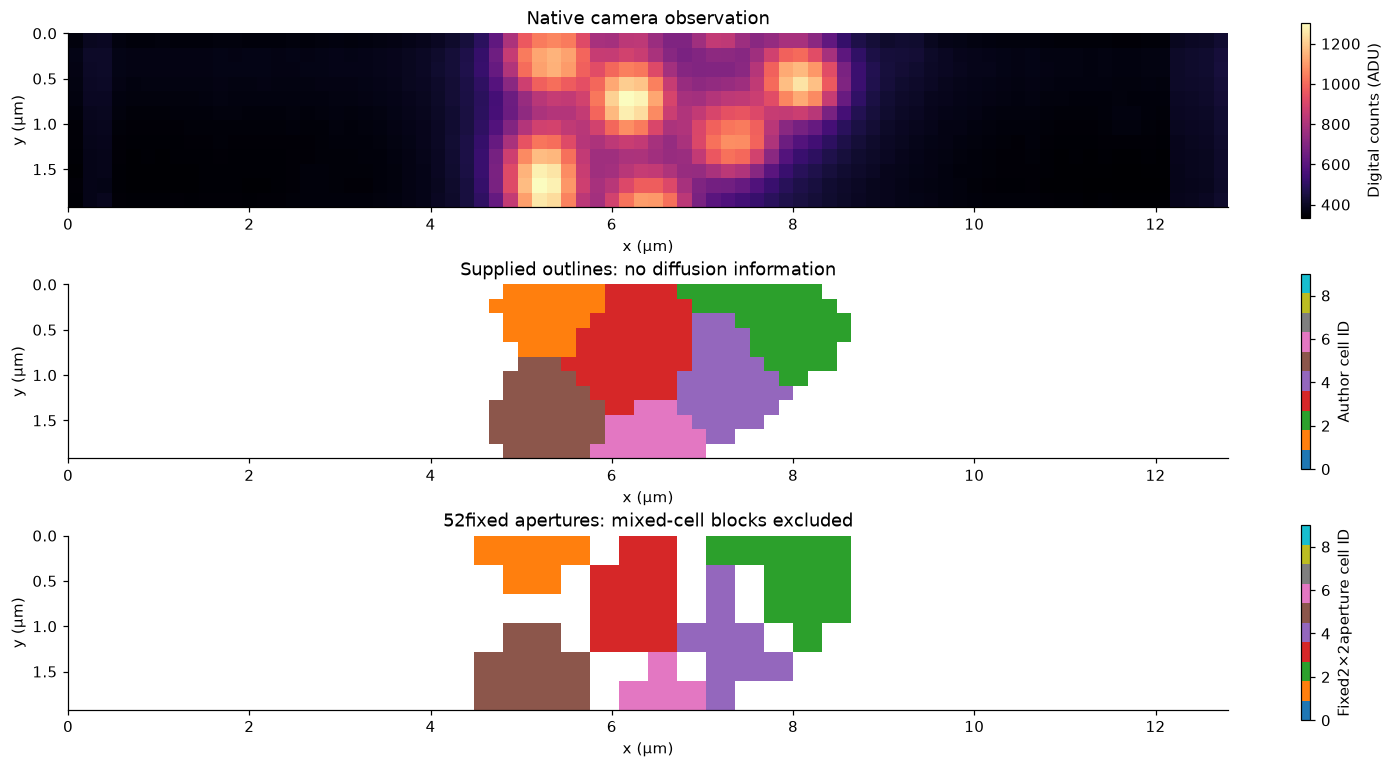

In [2]:
with np.load(TASK/'data/raw_data.npz',allow_pickle=False) as data:
    frames=data['frames'];cell_labels=data['cell_labels']
stack=prepare_stack(frames);labels=bin_labels(cell_labels);mask=labels>0
print({'native_movie':frames.shape,'retained_frames':len(stack),'cell_apertures':int(mask.sum()),'cell_ids':np.unique(labels[mask]).tolist(),'background_ADU':int(frames[0,1500:].min())})
extent=(0,12.8,1.92,0)
fig,ax=plt.subplots(3,1,figsize=(14,7))
im=ax[0].imshow(stack.mean(axis=0),extent=extent,cmap='magma');fig.colorbar(im,ax=ax[0],label='Digital counts (ADU)')
im=ax[1].imshow(np.ma.masked_equal(cell_labels[0],0),extent=extent,cmap='tab10',vmin=0,vmax=9,interpolation='nearest');fig.colorbar(im,ax=ax[1],label='Author cell ID')
im=ax[2].imshow(np.ma.masked_equal(labels,0),extent=extent,cmap='tab10',vmin=0,vmax=9,interpolation='nearest');fig.colorbar(im,ax=ax[2],label='Fixed2×2aperture cell ID')
for a,title in zip(ax,['Native camera observation','Supplied outlines: no diffusion information','52fixed apertures: mixed-cell blocks excluded']):
    a.set(title=title,xlabel='x (µm)',ylabel='y (µm)')
finish(fig,'01_real_observation_and_support')
numeric['mean_native_ADU']=stack.mean(axis=0);numeric['native_cell_labels']=cell_labels;numeric['output_cell_labels']=labels


## 3. Physics
Intensity fluctuations encode the time a fluorescent molecule spends in a blurred square observation aperture. The selected forward model is

$$G(\tau)=N^{-1}\left[\operatorname{erf}(\mu)+\frac{e^{-\mu^2}-1}{\sqrt{\pi}\mu}\right]^2+c,\qquad \mu=\frac{a}{2\sqrt{\sigma^2+fD\tau}}.$$

Here tau is lag in seconds, a=.32µm is the aperture side, sigma=.19µm is the independently calibrated Gaussian PSF standard deviation, f=2.1 is the published spherical-cell correction, D is inµm²/s, N is an effective molecular count, c is a signed dimensionless offset and erf is the error function. G is dimensionless normalized covariance. The product fD is identifiable; f and D separately are not. The original code embeds f in the fit, equivalent to fitting an apparent coefficient then dividing by2.1. Applying both would double-correct the result.

The squared bracket is the product of two identical one-dimensional Gaussian/aperture overlap factors. We independently integrate the triangular aperture autocorrelation against the diffusion Gaussian to check the formula. A finite curved membrane is represented by this effective calibrated model; exact3D membrane transport is not claimed.

In [3]:
# Independent physical check, without calling a copied forward formula.
lag_probe=np.geomspace(.0001,4.,40);Dprobe=.8;Nprobe=35.;cprobe=-.00003
quadrature=[]
for lag in lag_probe:
    variance=.19**2+2.1*Dprobe*lag
    overlap=quad(lambda s:(.32-abs(s))*np.exp(-s*s/(4*variance))/np.sqrt(4*np.pi*variance),-.32,.32,epsabs=1e-13)[0]/.32
    quadrature.append(overlap**2/Nprobe+cprobe)
analytic=correlation_model(lag_probe,Nprobe,Dprobe,cprobe)
print('Independent overlap-integral maximum error:',float(np.max(np.abs(analytic-quadrature))))
assert np.allclose(analytic,quadrature,rtol=1e-9,atol=1e-13)
numeric['quadrature_lags_s']=lag_probe;numeric['quadrature_covariance']=quadrature


Independent overlap-integral maximum error: 6.071532165918825e-18


## 4. Method
The active standard path uses only cleaned local NumPy/SciPy modules:

1. Average each fixed2×2cell aperture into an intensity time trace.
2. Fit a bounded double exponential plus constant to85nonoverlapping500-frame means; use the original variance-preserving correction on all42661frames. The last161samples are omitted from the envelope fit only.
3. Form an explicit pair-average multi-tau normalized covariance with16initial lag bins. The104positive lags exclude zero-lag shot noise. Original means and actual overlap counts are preserved at every temporal register.
4. Fit N,D,c jointly by the original unweighted unconstrained Levenberg–Marquardt objective across all104lags. Preserve initialization, finite-difference Jacobian, default stopping and floating arithmetic order. No spatial smoothing or regularizer is added.

For normalized trace z=I/max I and fitted mean b(j), the correction is

$$I_c(j)=\max(I)\left[\frac{z(j)}{\sqrt{b(j)/b(0)}}+b(0)\left(1-\sqrt{b(j)/b(0)}\right)\right].$$

j is the retained-frame index, Ic is corrected ADU and b is the normalized fitted double exponential. This differs from simply dividing by a fitted mean. Optional experiment settings below are explicitly labeled; they never replace the standard benchmark. All52standard fits must be physical and finite. No curve is discarded by its fit score.

In [4]:
started=time.perf_counter()
fresh,details=reconstruct(frames,cell_labels,return_details=True)
fresh_seconds=time.perf_counter()-started
np.savez_compressed(TASK/'output/reconstruction.npz',**fresh)
report,exit_code=judge.evaluate(TASK/'output/reconstruction.npz')
(TASK/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
assert exit_code==0,report
with np.load(TASK/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as archive:
    original={key:archive[key] for key in archive.files}
locations=[tuple(map(int,pos)) for pos in np.argwhere(mask)]
observed=np.array([details['curves'][pos][:,1] for pos in locations]);predicted=np.array([details['fits'][pos] for pos in locations]);lags=details['curves'][locations[0]][:,0]
print('Fresh standard reconstruction seconds:',fresh_seconds)
print(json.dumps(report,indent=2))
experiment_records['standard']={'seconds':fresh_seconds,'valid_apertures':52,'invalid':details['invalid_pixels'],'judge':report}
for key,value in fresh.items():numeric['fresh_'+key]=value;numeric['original_'+key]=original[key]
numeric['lags_s']=lags;numeric['observed_covariance']=observed;numeric['fresh_fitted_covariance']=predicted


Fresh standard reconstruction seconds: 0.4523348999937298
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 0.0,
    "molecule_number_ncc": 1.0,
    "molecule_number_nrmse": 0.0,
    "correlation_offset_ncc": 1.0,
    "correlation_offset_nrmse": 0.0,
    "correlation_residual": 0.09738480767333502
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1.076097913310491e-06
    },
    "molecule_number_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "molecule_number_nrmse": {
      "comparison": "<=",
      "boundary": 4.390633928035114e-07
    },
    "correlation_offset_ncc": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "correlation_offset_nrmse": {
      "comparison": "<=",
      "boundary": 2.4603767266767316e-07
    },
    "correlation_r

## 5. Results
The following plots all use the just-computed standard result or explicitly computed comparison runs. “Original rerun” means the independently executed author code on exactly this movie, never physical truth. Exact method agreement does not quantify biological accuracy. We show the data conditioning, per-curve physical consistency, all three recovered maps, numerical parity and calibration/resolution limitations.

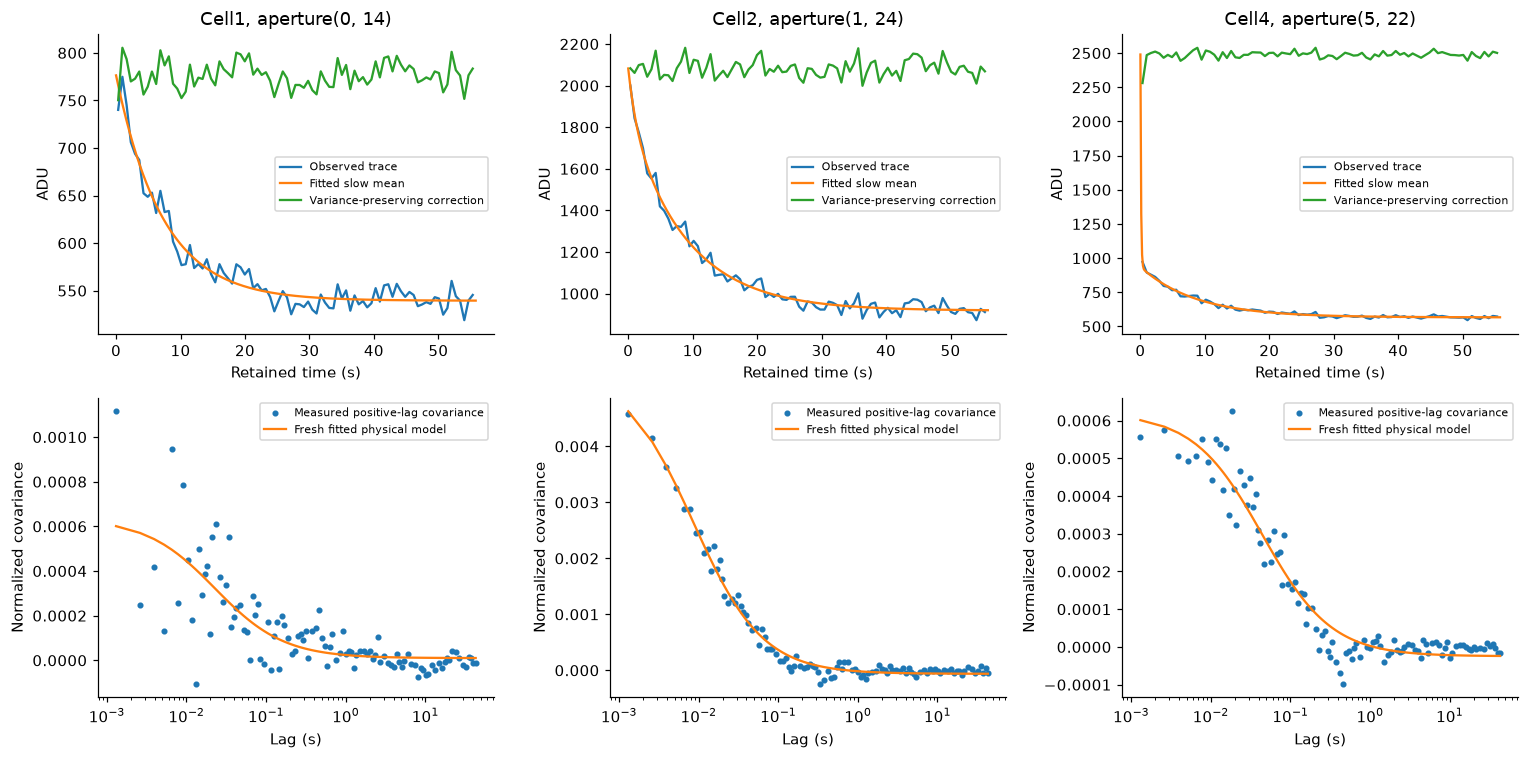

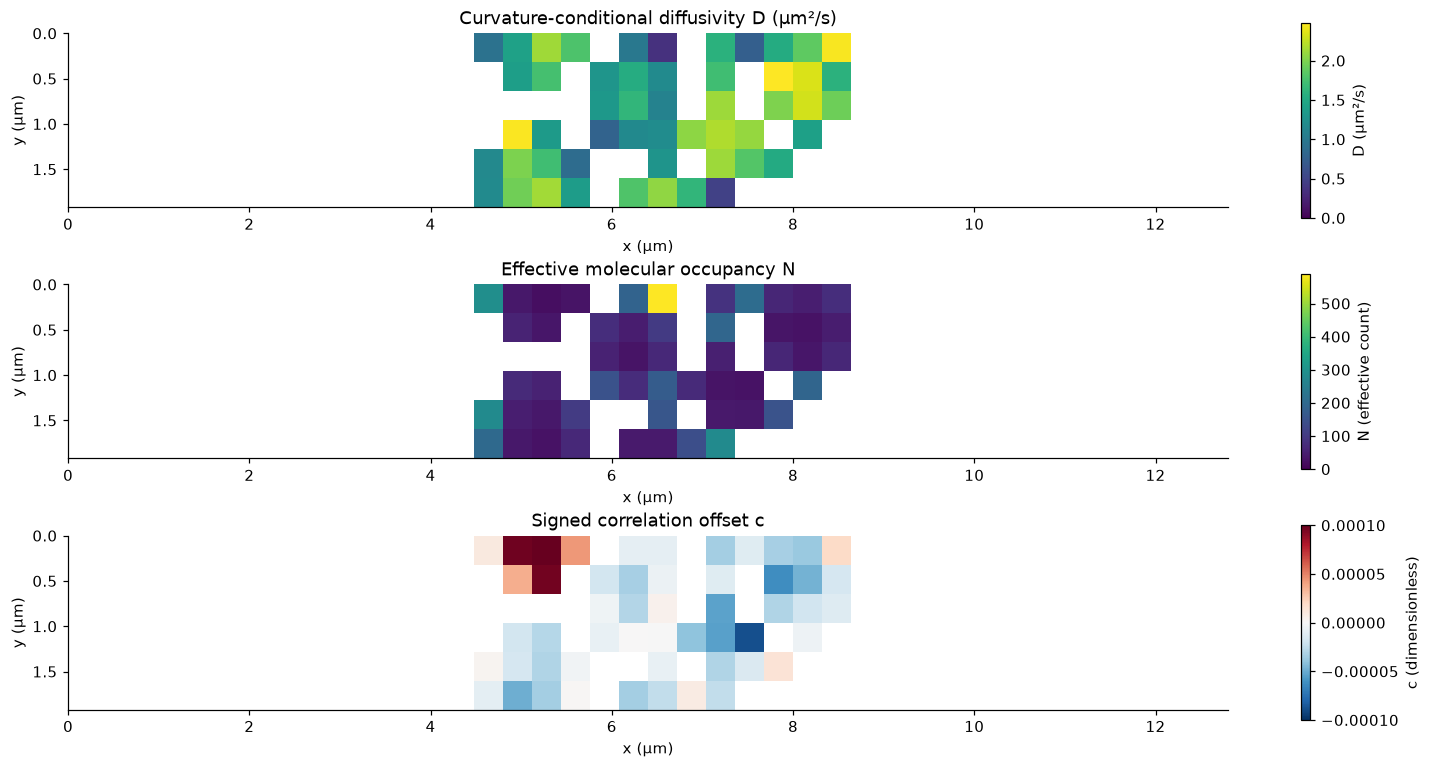

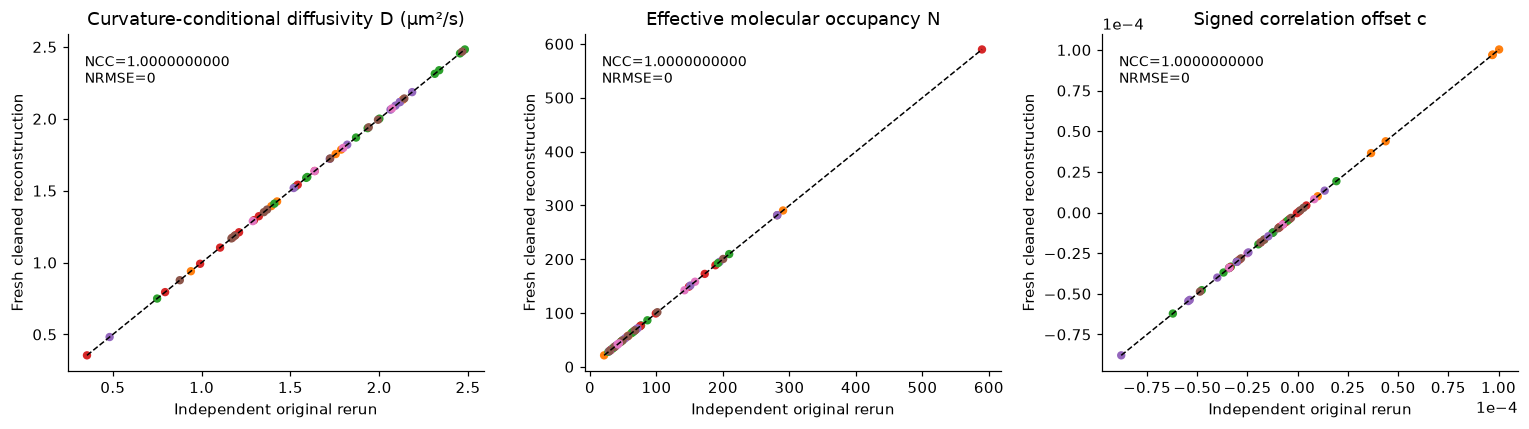

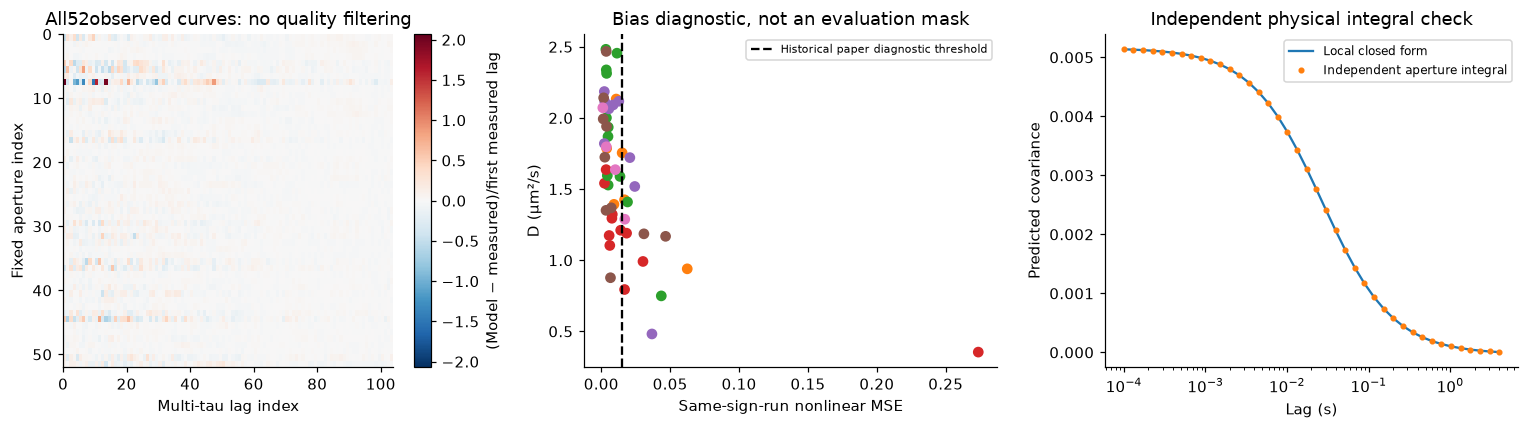

In [5]:
chosen=[locations[0],locations[17],locations[51]]
fig,axes=plt.subplots(2,3,figsize=(14,7))
for col,pos in enumerate(chosen):
    stage=details['bleaching'][pos];time_axis=np.arange(len(stage['raw_trace']))*.0013096382608637214
    # Plot500-frame means for readability; fitting/reconstruction uses every frame.
    count=len(time_axis)//500
    means=lambda arr:arr[:count*500].reshape(-1,500).mean(axis=1)
    t=means(time_axis)
    axes[0,col].plot(t,means(stage['raw_trace']),label='Observed trace')
    axes[0,col].plot(time_axis[::100],stage['envelope'][::100],label='Fitted slow mean')
    axes[0,col].plot(t,means(stage['corrected_trace']),label='Variance-preserving correction')
    axes[0,col].set(title=f'Cell{labels[pos]}, aperture{pos}',xlabel='Retained time (s)',ylabel='ADU');axes[0,col].legend(fontsize=7)
    curve=details['curves'][pos];fit=details['fits'][pos]
    axes[1,col].semilogx(curve[:,0],curve[:,1],'.',label='Measured positive-lag covariance')
    axes[1,col].semilogx(curve[:,0],fit,'-',label='Fresh fitted physical model')
    axes[1,col].set(xlabel='Lag (s)',ylabel='Normalized covariance');axes[1,col].legend(fontsize=7)
    numeric[f'trace_{col}_raw']=stage['raw_trace'];numeric[f'trace_{col}_corrected']=stage['corrected_trace'];numeric[f'trace_{col}_envelope']=stage['envelope']
finish(fig,'02_bleaching_and_measured_correlations')

fig,axes=plt.subplots(3,1,figsize=(14,7))
titles={'reconstruction':'Curvature-conditional diffusivity D (µm²/s)','molecule_number':'Effective molecular occupancy N','correlation_offset':'Signed correlation offset c'}
for ax,(key,title) in zip(axes,titles.items()):
    values=np.ma.array(fresh[key][0],mask=~mask)
    if key=='correlation_offset':
        bound=float(np.max(np.abs(values)));im=ax.imshow(values,extent=extent,cmap='RdBu_r',norm=TwoSlopeNorm(0,-bound,bound),interpolation='nearest')
    else:im=ax.imshow(values,extent=extent,cmap='viridis',vmin=0,interpolation='nearest')
    short_label={'reconstruction':'D (µm²/s)','molecule_number':'N (effective count)','correlation_offset':'c (dimensionless)'}[key]
    fig.colorbar(im,ax=ax,label=short_label);ax.set(title=title,xlabel='x (µm)',ylabel='y (µm)')
finish(fig,'03_three_recovered_parameter_maps')

fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,key in zip(axes,titles):
    x=original[key][0][mask];y=fresh[key][0][mask];lo=min(x.min(),y.min());hi=max(x.max(),y.max())
    ax.scatter(x,y,c=labels[mask],cmap='tab10',vmin=0,vmax=9,s=20);ax.plot([lo,hi],[lo,hi],'k--',lw=1)
    metric=vector_metrics(y,x);ax.set(title=titles[key],xlabel='Independent original rerun',ylabel='Fresh cleaned reconstruction')
    if key=='correlation_offset':ax.ticklabel_format(axis='both',style='sci',scilimits=(0,0))
    ax.text(.04,.94,f'NCC={metric["ncc"]:.10f}\nNRMSE={metric["nrmse"]:.3g}',transform=ax.transAxes,va='top',fontsize=9)
finish(fig,'04_original_fresh_all_parameter_parity')

nonlinear=np.array([nonlinear_mse(observed[i],predicted[i]) for i in range(len(locations))])
relative=(predicted-observed)/observed[:,0,None]
fig,axes=plt.subplots(1,3,figsize=(14,4))
bound=float(np.max(np.abs(relative)))
image=axes[0].imshow(relative,aspect='auto',cmap='RdBu_r',norm=TwoSlopeNorm(0,-bound,bound),extent=(0,104,52,0))
fig.colorbar(image,ax=axes[0],label='(Model − measured)/first measured lag');axes[0].set(xlabel='Multi-tau lag index',ylabel='Fixed aperture index',title='All52observed curves: no quality filtering')
axes[1].scatter(nonlinear,fresh['reconstruction'][0][mask],c=labels[mask],cmap='tab10',vmin=0,vmax=9)
axes[1].axvline(.015,color='k',ls='--',label='Historical paper diagnostic threshold')
axes[1].set(xlabel='Same-sign-run nonlinear MSE',ylabel='D (µm²/s)',title='Bias diagnostic, not an evaluation mask');axes[1].legend(fontsize=7)
axes[2].plot(lag_probe,analytic,label='Local closed form');axes[2].plot(lag_probe,quadrature,'o',ms=3,label='Independent aperture integral')
axes[2].set(xscale='log',xlabel='Lag (s)',ylabel='Predicted covariance',title='Independent physical integral check');axes[2].legend(fontsize=8)
finish(fig,'05_forward_consistency_and_quality_diagnostics')
numeric['normalized_correlation_residual']=relative;numeric['nonlinear_mse']=nonlinear
experiment_records['nonlinear_mse_above_historical_threshold']=int(np.count_nonzero(nonlinear>.015))


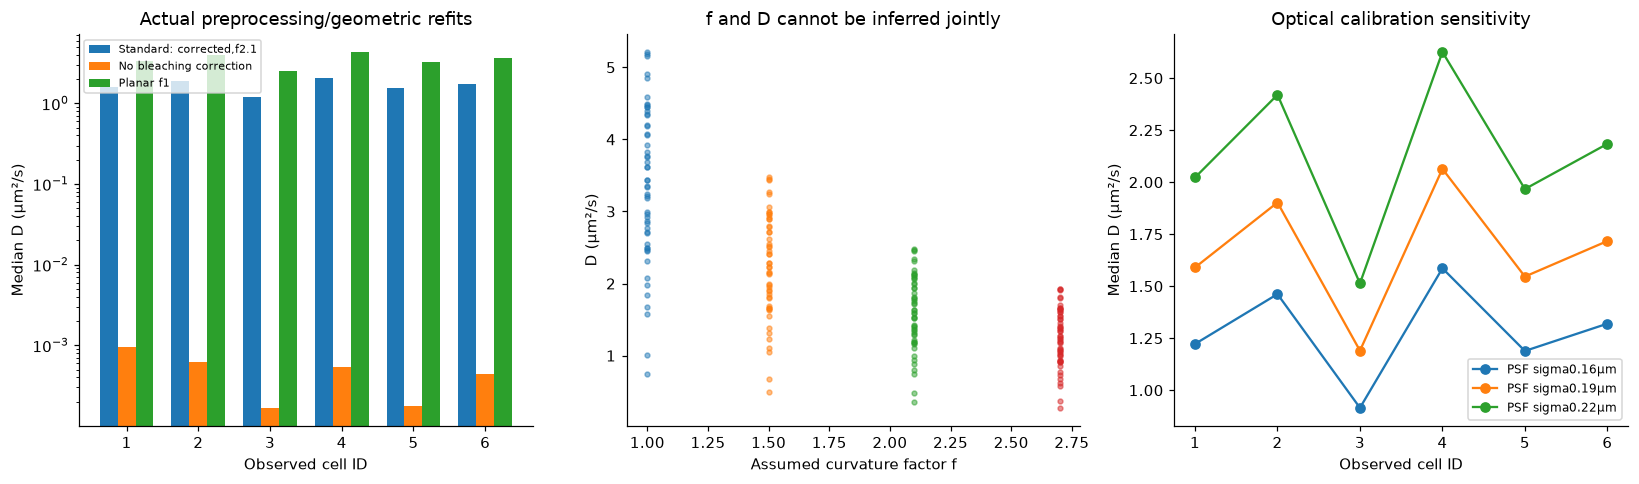

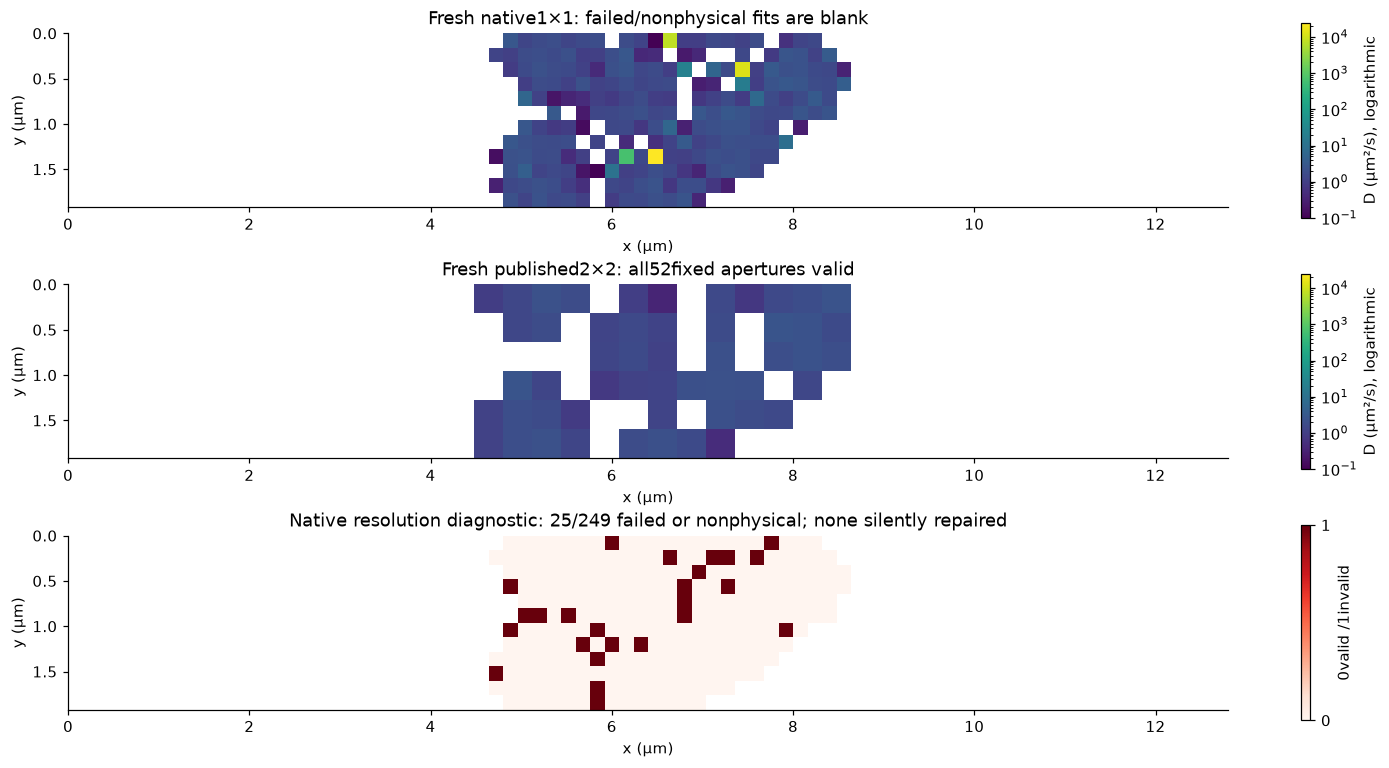

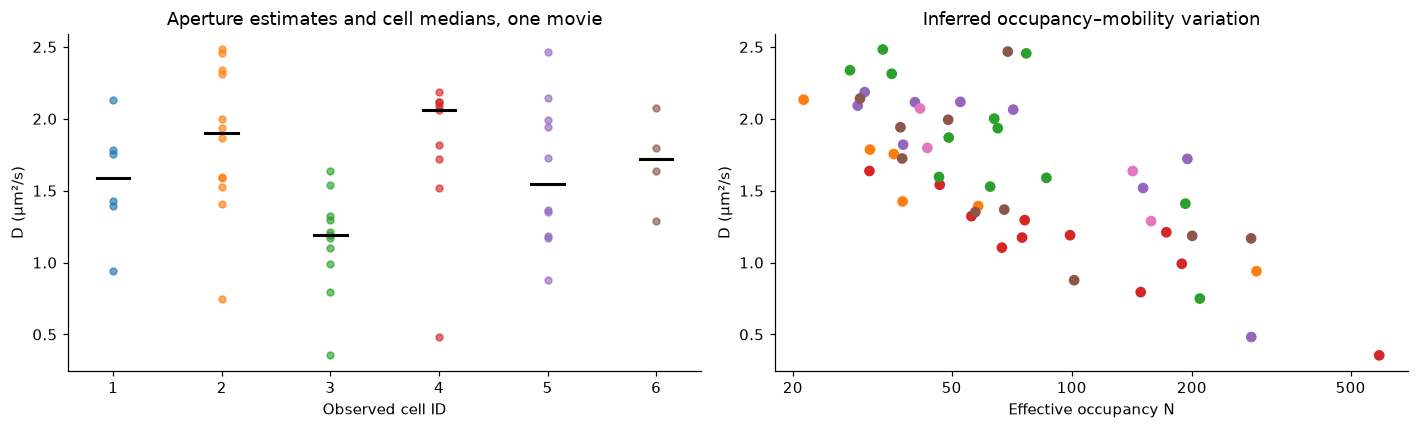

{
  "standard": {
    "seconds": 0.4523348999937298,
    "valid_apertures": 52,
    "invalid": [],
    "judge": {
      "status": "pass",
      "passed": true,
      "metrics": {
        "reconstruction_ncc": 1.0,
        "reconstruction_nrmse": 0.0,
        "molecule_number_ncc": 1.0,
        "molecule_number_nrmse": 0.0,
        "correlation_offset_ncc": 1.0,
        "correlation_offset_nrmse": 0.0,
        "correlation_residual": 0.09738480767333502
      },
      "thresholds": {
        "reconstruction_ncc": {
          "comparison": ">=",
          "boundary": 0.9999999999
        },
        "reconstruction_nrmse": {
          "comparison": "<=",
          "boundary": 1.076097913310491e-06
        },
        "molecule_number_ncc": {
          "comparison": ">=",
          "boundary": 0.9999999999
        },
        "molecule_number_nrmse": {
          "comparison": "<=",
          "boundary": 4.390633928035114e-07
        },
        "correlation_offset_ncc": {
          "compariso

In [6]:
# Actual fresh sensitivity runs: all52fixed standard apertures are retained.
comparisons={}
settings={'no_bleaching':{'bleaching':False},'planar_f1':{'curvature':1.},'f1p5':{'curvature':1.5},'f2p7':{'curvature':2.7},'sigma0p16':{'sigma':.16},'sigma0p22':{'sigma':.22}}
for name,kwargs in settings.items():
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always');result,record=reconstruct(frames,cell_labels,return_details=True,require_physical=False,**kwargs)
    comparisons[name]=(result,record)
    experiment_records[name]={'settings':kwargs,'seconds':record['runtime_seconds'],'invalid_apertures':record['invalid_pixels'],'warnings':len(caught)}
    for key,value in result.items():numeric[name+'_'+key]=value
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always');native,native_details=reconstruct(frames,cell_labels,binning=1,return_details=True,require_physical=False)
experiment_records['native_one_pixel']={'seconds':native_details['runtime_seconds'],'fixed_apertures':int((native_details['labels']>0).sum()),'invalid_apertures':native_details['invalid_pixels'],'warnings':len(caught)}
numeric['native_one_pixel_diffusion']=native['reconstruction'];numeric['native_one_pixel_labels']=native_details['labels']
cell_ids=np.unique(labels[mask]);medians=lambda result:np.array([np.median(result['reconstruction'][0][labels==cell]) for cell in cell_ids])
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
x=np.arange(len(cell_ids));width=.25
axes[0].bar(x-width,medians(fresh),width,label='Standard: corrected,f2.1')
axes[0].bar(x,medians(comparisons['no_bleaching'][0]),width,label='No bleaching correction')
axes[0].bar(x+width,medians(comparisons['planar_f1'][0]),width,label='Planar f1')
axes[0].set(yscale='log',xticks=x,xticklabels=cell_ids,xlabel='Observed cell ID',ylabel='Median D (µm²/s)',title='Actual preprocessing/geometric refits');axes[0].legend(fontsize=7)
for name,factor in [('planar_f1',1.),('f1p5',1.5),('standard',2.1),('f2p7',2.7)]:
    result=fresh if name=='standard' else comparisons[name][0]
    axes[1].scatter(np.full(mask.sum(),factor),result['reconstruction'][0][mask],s=10,alpha=.5)
axes[1].set(xlabel='Assumed curvature factor f',ylabel='D (µm²/s)',title='f and D cannot be inferred jointly')
for name,sigma in [('sigma0p16',.16),('standard',.19),('sigma0p22',.22)]:
    result=fresh if name=='standard' else comparisons[name][0]
    axes[2].plot(cell_ids,medians(result),'o-',label=f'PSF sigma{sigma}µm')
axes[2].set(xlabel='Observed cell ID',ylabel='Median D (µm²/s)',title='Optical calibration sensitivity');axes[2].legend(fontsize=8)
finish(fig,'06_bleaching_curvature_and_psf_refits')

native_mask=native_details['labels']>0;native_physical=native_mask&(native['reconstruction'][0]>0)&(native['molecule_number'][0]>0)
for pos in native_details['invalid_pixels']:native_physical[pos]=False
fig,axes=plt.subplots(3,1,figsize=(14,7))
vmax=max(float(np.max(native['reconstruction'][0][native_physical])),float(np.max(fresh['reconstruction'][0][mask])))
for ax,value,valid,title in [(axes[0],native['reconstruction'][0],native_physical,'Fresh native1×1: failed/nonphysical fits are blank'),(axes[1],fresh['reconstruction'][0],mask,'Fresh published2×2: all52fixed apertures valid')]:
    image=ax.imshow(np.ma.array(value,mask=~valid),extent=extent,cmap='viridis',norm=LogNorm(.1,vmax),interpolation='nearest');fig.colorbar(image,ax=ax,label='D (µm²/s), logarithmic');ax.set(title=title,xlabel='x (µm)',ylabel='y (µm)')
invalid=np.zeros(native_mask.shape)
for pos in native_details['invalid_pixels']:invalid[pos]=1
image=axes[2].imshow(np.ma.array(invalid,mask=~native_mask),extent=extent,cmap='Reds',vmin=0,vmax=1,interpolation='nearest');fig.colorbar(image,ax=axes[2],ticks=[0,1],label='0valid /1invalid')
axes[2].set(title=f'Native resolution diagnostic: {len(native_details["invalid_pixels"])}/{native_mask.sum()} failed or nonphysical; none silently repaired',xlabel='x (µm)',ylabel='y (µm)')
finish(fig,'07_spatial_resolution_and_invalid_fits')
numeric['native_one_pixel_physical_mask']=native_physical

fig,axes=plt.subplots(1,2,figsize=(13,4))
for cell in cell_ids:
    values=fresh['reconstruction'][0][labels==cell]
    axes[0].scatter(np.full(len(values),cell),values,s=20,alpha=.65)
    axes[0].plot([cell-.15,cell+.15],[np.median(values)]*2,'k-',lw=2)
axes[0].set(xlabel='Observed cell ID',ylabel='D (µm²/s)',title='Aperture estimates and cell medians, one movie')
axes[1].scatter(fresh['molecule_number'][0][mask],fresh['reconstruction'][0][mask],c=labels[mask],cmap='tab10',vmin=0,vmax=9)
axes[1].set(xscale='log',xlabel='Effective occupancy N',ylabel='D (µm²/s)',title='Inferred occupancy–mobility variation')
axes[1].set_xticks([20,50,100,200,500],labels=['20','50','100','200','500']);axes[1].xaxis.set_minor_locator(NullLocator());axes[1].xaxis.set_minor_formatter(NullFormatter())
finish(fig,'08_within_movie_cell_parameter_distributions')
if EXPORT:
    np.savez_compressed(EXPORT/'numerical_sources.npz',**numeric)
    (ARCHIVE/'scientific_measurements.json').write_text(json.dumps(experiment_records,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(experiment_records,indent=2))


## 6. Conclusion
We actively reconstructed all52fixed cell apertures from all42661stationary frames of the real native movie. D,N and c agree with the independent original rerun, and the independent Gaussian/aperture integral verifies the selected forward formula. The measured covariance residual provides a second, observation-based assessment rather than relying only on agreement with a method reference.

The fresh comparisons show why slow intensity drift, PSF calibration, curvature assumptions and aperture size must be separated from biological conclusions. The native single-pixel path has explicit failed/nonphysical fits, which remain missing in physical plots; the published2×2path has no such invalid outputs. We did not interpolate the52estimates, replace failures with zero-valued physical results, or discard high-residual apertures to improve reported metrics.

This benchmark reproduces a specific calibrated estimator on one real acquisition. It cannot prove true membrane viscosity, molecular trajectories, exact3D surface transport, or a temperature effect. Cell-to-cell and aperture-to-aperture distributions shown here are descriptive, not independent biological replicates. See test/validation.md for exact revisions, observation hashes, original and fresh environments, stage fixtures, numerical tolerances and execution evidence.